# 03 — NISAR multi-track, seasonal velocity of Siachen
Pakistan Glacier Intelligence Explorer · NASA Space Apps 2026 · *Dancing with the SARs*

Processes **every** NISAR GOFF file in `data/nisar/` (any track, ascending or descending), then:
1. culls & bias-corrects each pair and puts it on one common 80 m UTM grid,
2. median-stacks pairs per **season** (winter = Nov–Apr, summer = May–Oct) and per viewing geometry,
3. inverts for velocity — **3-D (east, north, up)** where both ascending and descending data exist,
   horizontal-only (surface-parallel assumption) where only one geometry exists,
4. compares seasons and validates against ITS_LIVE.

Processing code lives in `src/pgie/nisar.py` (tested by `tests/test_inversion.py`).

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_DIR = Path(r"D:\Pakistan Glacier Intelligence Explorer")
sys.path.insert(0, str(PROJECT_DIR / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pgie.common import NISAR_DIR, PROCESSED_DIR, RESULTS_DIR, FIGURES_DIR, save_tif
from pgie.nisar import find_pairs, common_grid, its_median_on_grid, process_pair, combine

OUT = PROCESSED_DIR / "nisar_combined"; OUT.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9})

grid = common_grid()
its = its_median_on_grid(grid)          # ITS_LIVE 2017–22 median speed (from notebook 02)
ice, rock = its >= 15, its <= 3
print("Common grid:", grid.shape, grid.crs, "| ice px:", int(ice.sum()), "| rock px:", int(rock.sum()))

Common grid: (776, 640) EPSG:32643 | ice px: 120589 | rock px: 298629


## 1. Inventory of NISAR pairs

In [2]:
pairs = find_pairs(NISAR_DIR)
inv = pd.DataFrame([{"pair": p.tag, "geometry": p.geometry, "frame": p.frame, "from": p.ref.date(), "to": p.sec.date(),
                     "days": round(p.days, 1), "season": p.season, "release": p.crid,
                     "size_GB": round(p.path.stat().st_size / 1e9, 2)} for p in pairs])
inv

,pair,geometry,frame,from,to,days,season,release,size_GB
0,135D071_20251119_20251201,135D,71,2025-11-19,2025-12-01,12.0,winter,X05010,0.91
1,055A019_20251220_20260101,055A,19,2025-12-20,2026-01-01,12.0,winter,X05010,1.18
2,055A019_20260101_20260113,055A,19,2026-01-01,2026-01-13,12.0,winter,X05010,1.17
3,135D071_20260106_20260118,135D,71,2026-01-06,2026-01-18,12.0,winter,X05010,0.93
4,135D071_20260705_20260717,135D,71,2026-07-05,2026-07-17,12.0,summer,P05023,1.10
5,055A019_20260712_20260724,055A,19,2026-07-12,2026-07-24,12.0,summer,P05023,1.17
6,055A019_20260817_20260829,055A,19,2026-08-17,2026-08-29,12.0,summer,P05023,1.14


## 2. Process every pair (crop → cull → bias → common grid)

In [3]:
results, rows = [], []
for p in pairs:
    try:
        r = process_pair(p, grid, rock_mask=rock)
    except ValueError as e:
        print("skip:", e); continue
    results.append(r)
    sp = np.hypot(r.v_at, r.v_sr)
    rows.append({"pair": p.tag, "season": p.season, "layer": r.layer,
                 "valid_on_ice_%": round(100 * np.isfinite(r.v_at[ice]).mean(), 1),
                 "slant_range_bias_m": round(r.stats["bias_sr_m"], 2),
                 "rock_noise_m_per_yr": round(r.stats["rock_noise_m_yr"], 1)})
pair_stats = pd.DataFrame(rows)
pair_stats.to_csv(RESULTS_DIR / "nisar_pair_quality.csv", index=False)
pair_stats

,pair,season,layer,valid_on_ice_%,slant_range_bias_m,rock_noise_m_per_yr
0,135D071_20251119_20251201,winter,layer2,59.6,5.12,26.5
1,055A019_20251220_20260101,winter,layer1,64.0,-0.12,19.0
2,055A019_20260101_20260113,winter,layer1,78.7,-0.30,14.9
3,135D071_20260106_20260118,winter,layer2,57.3,0.08,28.1
4,135D071_20260705_20260717,summer,layer2,21.5,-1.29,32.5
5,055A019_20260712_20260724,summer,layer2,48.2,0.08,18.5
6,055A019_20260817_20260829,summer,layer2,60.8,0.76,13.6


## 3. Seasonal stacks and velocity inversion

In [4]:
seasons = combine(results, group_by="season")
summary = []
for s, m in seasons.items():
    for k in ("ve", "vn", "vu", "speed"):
        save_tif(OUT / f"siachen_nisar_{s}_{k}.tif", m[k], grid.transform, grid.crs)
    save_tif(OUT / f"siachen_nisar_{s}_n_geometries.tif", m["n_geom"].astype("float32"), grid.transform, grid.crs)
    sp = m["speed"][ice]
    summary.append({"season": s, "pairs": m["n_pairs"], "geometries": "+".join(m["geometries"]),
                    "ice measured %": round(100 * np.isfinite(sp).mean(), 1),
                    "ice with 3-D solution %": round(100 * (m["n_geom"][ice] >= 2).mean(), 1),
                    "median ice speed m/yr": round(float(np.nanmedian(sp)), 1),
                    "p90 ice speed m/yr": round(float(np.nanpercentile(sp[np.isfinite(sp)], 90)), 1)})
season_df = pd.DataFrame(summary).sort_values("season", ascending=False)
season_df.to_csv(RESULTS_DIR / "nisar_seasonal_summary.csv", index=False)
season_df

,season,pairs,geometries,ice measured %,ice with 3-D solution %,median ice speed m/yr,p90 ice speed m/yr
0,winter,4,055A+135D,90.0,56.7,47.3,113.3
1,summer,3,055A+135D,67.5,19.3,67.8,150.7


## 4. Validation against ITS_LIVE (spatial pattern & flow direction)

In [5]:
import rasterio
from pgie.common import read_tif
from pgie.nisar import to_grid
from rasterio.warp import Resampling
from pyproj import Transformer

# ITS_LIVE median vx/vy (2017–22) rotated from ESRI:102027 axes into UTM east/north
def its_vec():
    vx, t, c = read_tif(PROCESSED_DIR / "its_live_siachen" / "siachen_2022_vx.tif")
    vxs = np.nanmedian([read_tif(PROCESSED_DIR / "its_live_siachen" / f"siachen_{y}_vx.tif")[0] for y in range(2017, 2023)], 0)
    vys = np.nanmedian([read_tif(PROCESSED_DIR / "its_live_siachen" / f"siachen_{y}_vy.tif")[0] for y in range(2017, 2023)], 0)
    tr = Transformer.from_crs(c, grid.crs, always_xy=True)
    cx, cy = t.c + t.a * vx.shape[1] / 2, t.f + t.e * vx.shape[0] / 2
    (x0, x1), (y0, y1) = tr.transform([cx, cx + 1000], [cy, cy])
    a = np.arctan2(y1 - y0, x1 - x0)
    ve, vn = vxs * np.cos(a) - vys * np.sin(a), vxs * np.sin(a) + vys * np.cos(a)
    return to_grid(ve, t, c, grid, Resampling.bilinear), to_grid(vn, t, c, grid, Resampling.bilinear)
its_ve, its_vn = its_vec()

val = []
for s, m in seasons.items():
    sel = ice & np.isfinite(m["speed"])
    fast = sel & (its >= 40)
    cosang = (m["ve"][fast] * its_ve[fast] + m["vn"][fast] * its_vn[fast]) / (m["speed"][fast] * np.hypot(its_ve[fast], its_vn[fast]))
    ang = np.degrees(np.arccos(np.clip(cosang, -1, 1)))
    val.append({"season": s, "pixels": int(sel.sum()),
                "speed correlation r": round(np.corrcoef(m["speed"][sel], its[sel])[0, 1], 2),
                "NISAR/ITS_LIVE speed ratio": round(float(np.nanmedian(m["speed"][sel] / its[sel])), 2),
                "median direction diff (deg)": round(float(np.median(ang)), 1),
                "% within 30°": round(float((ang <= 30).mean() * 100), 1)})
val_df = pd.DataFrame(val)
val_df.to_csv(RESULTS_DIR / "nisar_seasonal_validation.csv", index=False)
val_df

,season,pixels,speed correlation r,NISAR/ITS_LIVE speed ratio,median direction diff (deg),% within 30°
0,winter,108474,0.69,0.69,7.0,90.1
1,summer,81400,0.53,0.94,10.3,86.3


## 5. Maps

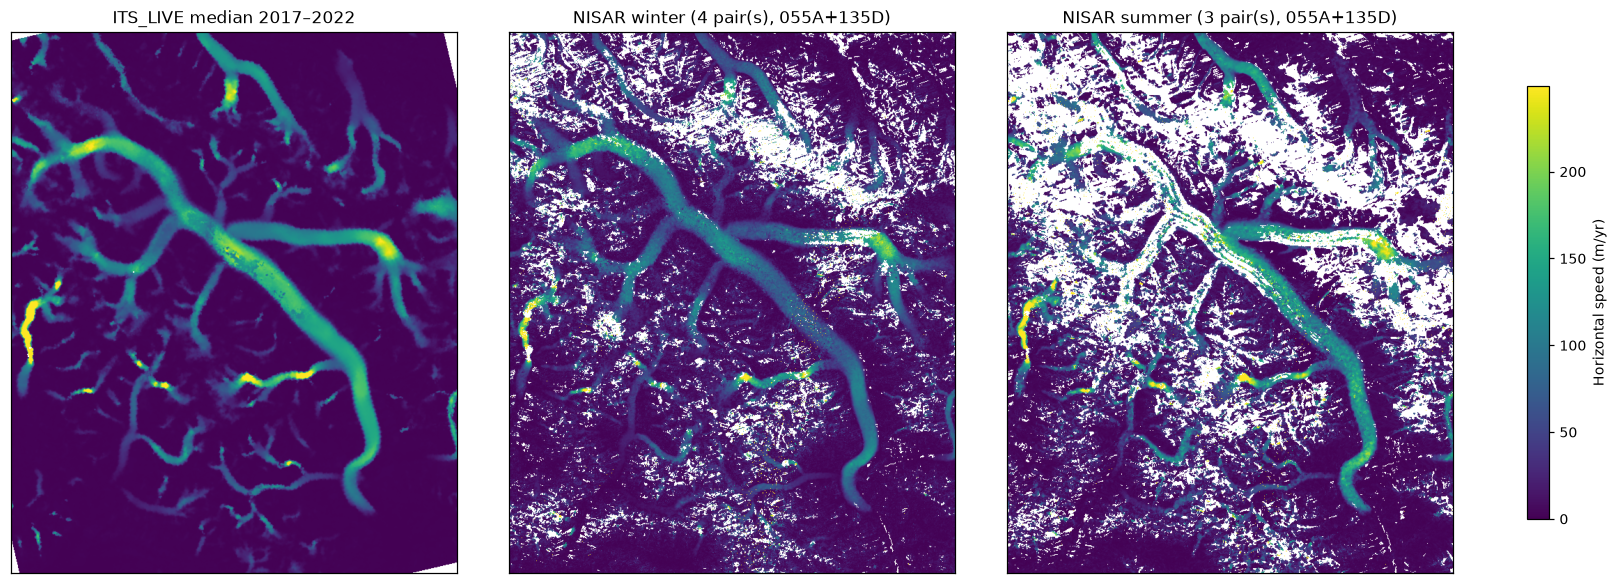

In [6]:
order = [s for s in ("winter", "summer") if s in seasons]
vmax = np.nanpercentile(its[ice], 99)
fig, axes = plt.subplots(1, len(order) + 1, figsize=(5 * (len(order) + 1), 5.2), constrained_layout=True)
axes = np.atleast_1d(axes)
im = axes[0].imshow(its, cmap="viridis", vmin=0, vmax=vmax); axes[0].set_title("ITS_LIVE median 2017–2022")
for ax, s in zip(axes[1:], order):
    ax.imshow(seasons[s]["speed"], cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"NISAR {s} ({seasons[s]['n_pairs']} pair(s), {'+'.join(seasons[s]['geometries'])})")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="Horizontal speed (m/yr)")
fig.savefig(FIGURES_DIR / "nisar_seasonal_speed.png"); plt.show()

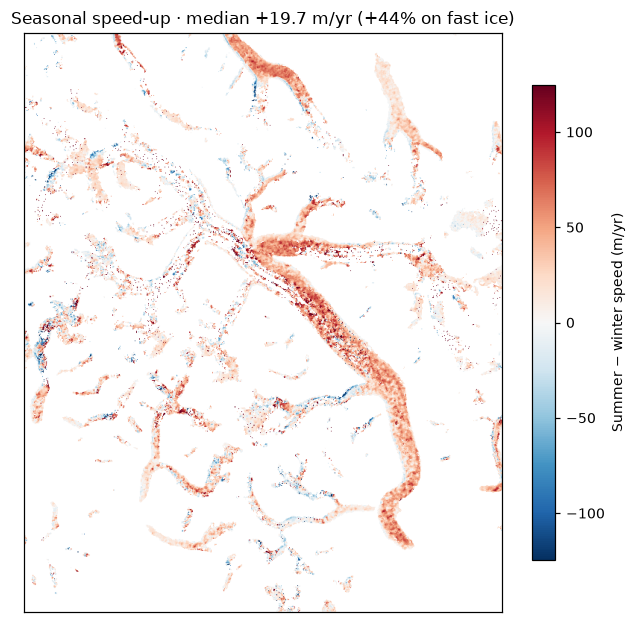

In [7]:
if {"winter", "summer"} <= set(seasons):
    d = seasons["summer"]["speed"] - seasons["winter"]["speed"]
    d = np.where(ice, d, np.nan)
    pct = 100 * d / seasons["winter"]["speed"]
    lim = np.nanpercentile(np.abs(d), 98)
    fig, ax = plt.subplots(figsize=(7, 7))
    im = ax.imshow(d, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8, label="Summer − winter speed (m/yr)")
    ax.set_title(f"Seasonal speed-up · median {np.nanmedian(d):+.1f} m/yr ({np.nanmedian(pct[np.isfinite(pct) & (its >= 40)]):+.0f}% on fast ice)")
    save_tif(OUT / "siachen_nisar_summer_minus_winter.tif", d, grid.transform, grid.crs)
    fig.savefig(FIGURES_DIR / "nisar_summer_minus_winter.png"); plt.show()
else:
    print("Only one season available so far:", list(seasons), "— download pairs from the other season to see seasonal change.")

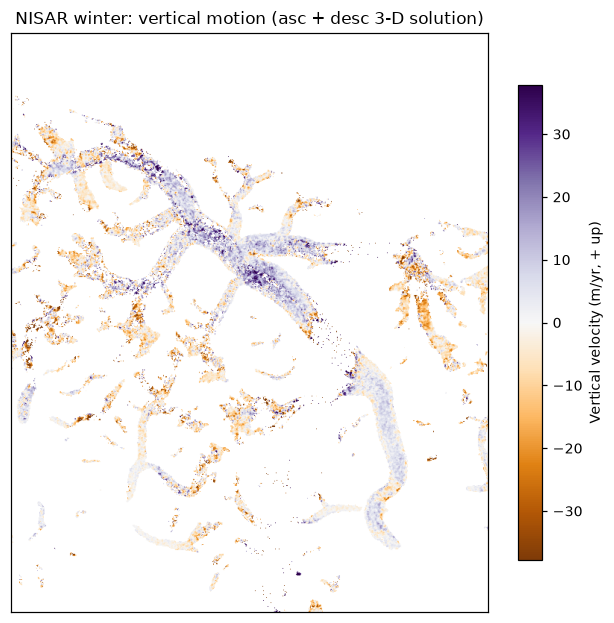

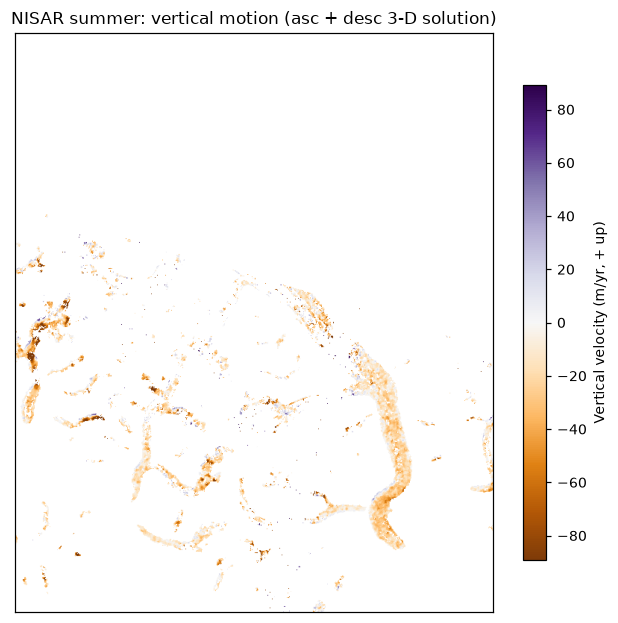

In [8]:
for s in order:
    m = seasons[s]
    if (m["n_geom"] >= 2).any():
        vu = np.where(ice & (m["n_geom"] >= 2), m["vu"], np.nan)
        lim = np.nanpercentile(np.abs(vu), 98)
        fig, ax = plt.subplots(figsize=(7, 7))
        im = ax.imshow(vu, cmap="PuOr", vmin=-lim, vmax=lim); ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, shrink=0.8, label="Vertical velocity (m/yr, + up)")
        ax.set_title(f"NISAR {s}: vertical motion (asc + desc 3-D solution)")
        fig.savefig(FIGURES_DIR / f"nisar_{s}_vertical.png"); plt.show()
    else:
        print(f"{s}: single geometry only — no vertical solution (needs ascending + descending).")

## Outputs
| What | Where |
|---|---|
| Seasonal east / north / up / speed / n-geometries GeoTIFFs | `processed/nisar_combined/` |
| Per-pair quality, seasonal summary, validation | `results/nisar_*.csv` |
| Figures | `results/figures/nisar_seasonal_*.png` |

Next: `scripts/export_web_layers.py` turns these into layers for the web app.